# 14. Adding anomaly flags to an early-warning model (Week 5)

**Owner:** Rishi. Task from the plan: *contribute anomaly flags to the models.*

**Target (project definition):** on day *t*, does a stress episode start in the next 20 trading days? Days already inside an episode are excluded, since the question is early warning.

**Models** (logistic regression, class-balanced, `src/alerts.py`):
* **Baseline:** VIX level, 20-day change in VIX, trailing 20-day realized S&P 500 (SPY) volatility. This is the team's agreed baseline (VIX + past volatility).
* **+ z-scores:** baseline plus the network z-scores from notebook 13.
* **+ z-scores + IF:** also the Isolation Forest score.

**Walk-forward:** refit at the start of each year from 2010 on, on past data only. A training day *t* is used only if its 20-day outcome was already known before the refit date (purge). The alert threshold is the 90th percentile of training probabilities, also fixed before the test year. All three models are scored on the **same** test days.

Note: Fatima's notebook 10 predicts the contemporaneous `stress` label with an 80/20 split; this notebook uses the forward-looking target from the project plan, so the numbers are not directly comparable.

In [1]:
import os
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Works from the repo root or from notebooks/. RGBFS_DATA_ROOT is only for test runs on fake data.
CODE_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "anomaly.py").exists())
DATA_ROOT = Path(os.environ.get("RGBFS_DATA_ROOT", CODE_ROOT))
sys.path.insert(0, str(CODE_ROOT))

from src import anomaly as an
from src import alerts as al

PROC = DATA_ROOT / "data" / "processed"
FEATURES = PROC / "features"
EPISODES_CSV = DATA_ROOT / "docs" / "stress_periods.csv"
OUT = DATA_ROOT / "notebooks" / "outputs" / "rishi_week5"
OUT.mkdir(parents=True, exist_ok=True)
print("Code:", CODE_ROOT)
print("Data:", DATA_ROOT)

Code: /home/claude/rgbfs
Data: /home/claude/rgbfs


## 1. Build the daily dataset

In [2]:
panel = pd.read_parquet(PROC / "daily_panel.parquet").sort_index()
panel.index = pd.to_datetime(panel.index)
cal = panel.index
labels = pd.read_parquet(PROC / "stress_labels_daily.parquet")
label_end = labels["stress"].last_valid_index()
episodes = al.load_episodes(EPISODES_CSV)

masks = al.episode_masks(cal, episodes, horizon=al.HORIZON, label_end=label_end)
base = pd.DataFrame(index=cal)
base["vix"] = panel["VIXCLS"].ffill(limit=3)
base["vix_chg20"] = base["vix"] - base["vix"].shift(20)
base["rv20"] = panel["SPY_ret"].rolling(20).std() * np.sqrt(252)

anom = pd.read_parquet(FEATURES / "anomaly_network_daily.parquet").reindex(cal)
Z_FEATS = ["z_avg_corr", "z_absorption", "z_avg_corr_chg", "z_absorption_chg", "z_composite"]
data = masks.join(base).join(anom[Z_FEATS + ["if_score"]])

# SEC filing sentiment (scripts/build_sentiment.py), when built: market-wide tone of the 50 firms' latest filings
SENT_FEATS = []
sent_path = FEATURES / "sec_sentiment_market_daily.parquet"
if sent_path.exists():
    # MD&A only: every filing has one, so this model is scored on the same test days as the others.
    # (The Risk Factors share is often missing, when no firm wrote new risk paragraphs; it is tested in notebook 15.)
    SENT_FEATS = ["mdna_sentiment", "mdna_tone_change"]
    data = data.join(pd.read_parquet(sent_path).reindex(cal)[SENT_FEATS])

MODELS = {
    "baseline": ["vix", "vix_chg20", "rv20"],
    "+ z-scores": ["vix", "vix_chg20", "rv20"] + Z_FEATS,
    "+ z-scores + IF": ["vix", "vix_chg20", "rv20"] + Z_FEATS + ["if_score"],
}
if SENT_FEATS:
    MODELS["+ filing sentiment"] = ["vix", "vix_chg20", "rv20"] + SENT_FEATS
print("Eligible days:", int(data.eligible.sum()), " positive (episode starts within 20 days):", int(data.loc[data.eligible.eq(1), "target"].sum()))
print("Labels known through", label_end.date())

Eligible days: 6337  positive (episode starts within 20 days): 260
Labels known through 2026-10-14


## 2. Walk-forward predictions

In [3]:
# Baseline and "+ z-scores" train on the same rows (z-scores exist from about a year after the data start).
# The Isolation Forest score only starts after its 3-year warm-up, so that model trains on fewer rows.
# All three are then scored on the same test days.
common = data.dropna(subset=MODELS["+ z-scores"]).index
preds = {name: al.walk_forward_classifier(data.loc[common], feats, first_test_year=2010)
         for name, feats in MODELS.items()}
test_days = sorted(set.intersection(*[set(p.index) for p in preds.values()]))
preds = {k: v.loc[test_days] for k, v in preds.items()}
print("Common test days:", len(test_days), "from", test_days[0].date(), "to", test_days[-1].date())

Common test days: 3573 from 2011-01-03 to 2026-09-16


In [4]:
metrics = pd.DataFrame({k: al.classifier_metrics(v) for k, v in preds.items()}).T
metrics.round(3)

,test_days,positive_days,roc_auc,pr_auc,base_rate,precision,recall,false_alarm_rate
baseline,3573.0,180.0,0.624,0.090,0.05,0.140,0.183,0.060
+ z-scores,3573.0,180.0,0.602,0.064,0.05,0.062,0.128,0.102
+ z-scores + IF,3573.0,180.0,0.491,0.045,0.05,0.051,0.178,0.177


## 3. Lead times from each model's alerts

Same episode-level scoring as notebook 13, so the models can be compared with the raw anomaly flags.

In [5]:
rows = []
for col in ["start", "start_trailing"]:
    for name, p in preds.items():
        flag = p["alert"].reindex(cal)
        flag[(flag.isna()) & cal.isin(cal[(cal >= p.index.min()) & (cal <= p.index.max())])] = 0  # in-episode days = no alert
        rows.append(al.summarize_signal(name, flag, episodes, start_col=col))
lead_summary = pd.DataFrame(rows)
lead_summary[["signal", "start_col", "episodes_scored", "warned_early", "late", "missed", "median_lead_days", "false_alarms_per_year"]].round(2)

,signal,start_col,episodes_scored,warned_early,late,missed,median_lead_days,false_alarms_per_year
0,baseline,start,9,5,0,4,28.0,1.02
1,+ z-scores,start,9,4,0,5,33.0,2.23
2,+ z-scores + IF,start,9,5,0,4,36.0,1.97
3,baseline,start_trailing,9,5,1,3,38.0,1.08
4,+ z-scores,start_trailing,9,4,0,5,43.0,2.23
5,+ z-scores + IF,start_trailing,9,5,0,4,37.0,1.97


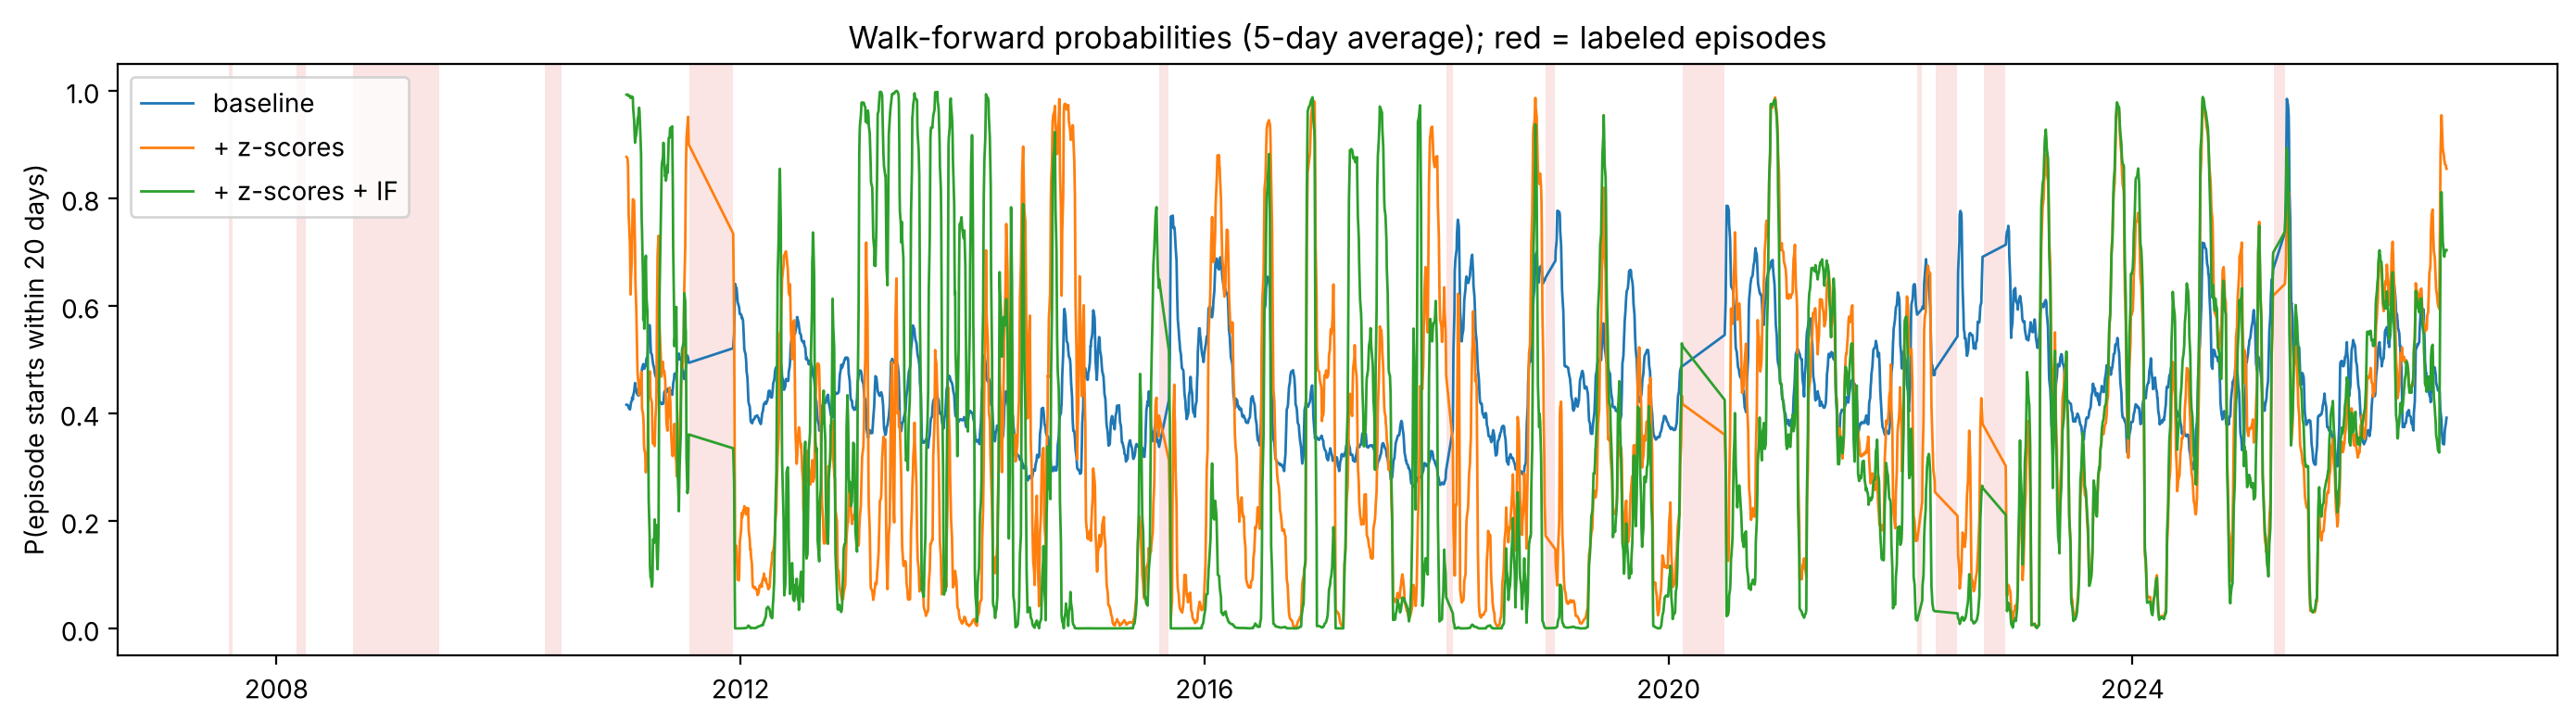

In [6]:
fig, ax = plt.subplots(figsize=(14, 4))
for name, p in preds.items():
    ax.plot(p.index, p.prob.rolling(5).mean(), lw=1, label=name)
for _, ep in episodes.iterrows():
    ax.axvspan(ep.start, ep.end, color="tab:red", alpha=0.12, lw=0)
ax.set_ylabel("P(episode starts within 20 days)")
ax.set_title("Walk-forward probabilities (5-day average); red = labeled episodes")
ax.legend()
plt.tight_layout(); plt.savefig(OUT / "walk_forward_probabilities.png", dpi=120); plt.show()

## 4. Coefficients in the last fold

Standardized logistic coefficients, so their sizes are comparable. Positive = raises the predicted chance of an episode starting soon. This is descriptive, not a significance test (the features are correlated).

In [7]:
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
feats = MODELS["+ z-scores + IF"]
last = preds["+ z-scores + IF"]
train = data.loc[common]
pos = pd.Series(np.arange(len(cal)), index=cal)
train = train[(pos.reindex(train.index) + al.HORIZON < pos[last.index.min()]) & train.eligible.eq(1)].dropna(subset=feats)
Xs = StandardScaler().fit_transform(train[feats])
coef = pd.Series(LogisticRegression(class_weight="balanced", max_iter=2000).fit(Xs, train.target).coef_[0], index=feats)
coef.sort_values().round(3)

vix                -3.149
rv20               -2.069
z_avg_corr         -1.058
z_avg_corr_chg     -0.658
z_composite        -0.493
z_absorption       -0.398
if_score            0.008
z_absorption_chg    1.639
vix_chg20           2.169
dtype: float64

## 5. Save outputs

The prediction tables are small enough for GitHub (`notebooks/outputs/rishi_week5/`). Notebook 15 and the dashboard read `model_alerts_daily.csv`.

In [8]:
metrics.to_csv(OUT / "model_metrics.csv")
lead_summary.to_csv(OUT / "model_lead_summary.csv", index=False)
wide = pd.concat({k: v[["prob", "alert"]] for k, v in preds.items()}, axis=1)
wide.columns = [f"{m}|{c}" for m, c in wide.columns]
wide.index.name = "date"
wide.join(data[["target"]]).to_csv(OUT / "model_alerts_daily.csv")
print("Saved to", OUT)

Saved to /home/claude/rgbfs/notebooks/outputs/rishi_week5


## 6. Findings (real data; rerun 2026-11-21 after the absorption fix)

Test days: 3,573 (2012 to 2026), 180 followed by an episode start within 20 days (base rate 5.0%), 9 episodes.

| Model | ROC-AUC | PR-AUC | Episodes warned early (of 9) | False alarms per year |
|---|---|---|---|---|
| Baseline (VIX, VIX change, realized vol) | 0.624 | 0.090 | 5 | 1.0 |
| + network z-scores | 0.602 | 0.064 | 4 | 2.2 |
| + z-scores + Isolation Forest | 0.491 | 0.045 | 5 | 2.0 |

(First run, with the stuck absorption ratio: + z-scores 0.479 / 0.045, + IF 0.395 / 0.038.)

* **The baseline is weak but better than chance:** PR-AUC 0.090 against a 0.050 base rate.
* **Adding the network features still does not help:** both enhanced models score below the baseline on ROC-AUC and PR-AUC, and they double the false alarms. The fix narrowed the gap but did not reverse it.
* **This agrees with Salah's independent check** (`notebooks/13_lookahead_check.ipynb`, scenario C): for the early-warning target, VIX only scores ROC-AUC 0.57 and the combined model 0.49.
* **Possible reason (not tested):** network z-scores are highest during and just after an episode, and those aftermath days count as "no new episode coming", so a model that learns "high z = stress soon" fires on them.
* **Caveat:** 9 test episodes is a small sample, and overlapping 20-day targets make neighboring days dependent.